# Apuração de aprovados: qualidade do cruzamento e resultados

Este notebook responde duas perguntas:

1. **O cruzamento é confiável?** Quantos alunos ele acerta, quantos erra e quanto trabalho manual sobra.
2. **Qual foi o resultado da apuração?** Quantos alunos passaram, onde e em quê.

Os dados são sintéticos (ver `scripts/gerar_dados.py`). A vantagem é que existe um gabarito com a
resposta certa, o que permite medir a qualidade do cruzamento, coisa que com dados reais exigiria
conferir caso a caso.

Antes de rodar: `uv run python scripts/gerar_dados.py` e `uv run python -m apuracao_aprovados.main`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from apuracao_aprovados.banco import consultar, ler_consultas
from apuracao_aprovados.cruzar import avaliar, cruzar

RAIZ = Path.cwd().parent
BANCO = RAIZ / "data" / "processed" / "apuracao.sqlite"
IMG = RAIZ / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

resultado = pd.read_csv(RAIZ / "data" / "processed" / "resultado_cruzamento.csv",
                        dtype={"id_aluno": "Int64", "cpf_parcial": str})
alunos = pd.read_csv(RAIZ / "data" / "raw" / "alunos.csv", dtype={"cpf": str})
gabarito = pd.read_csv(RAIZ / "data" / "gabarito" / "gabarito.csv", dtype={"id_aluno": "Int64"})
print(f"{len(resultado)} nomes extraídos dos PDFs | {len(alunos)} alunos na base")

3258 nomes extraídos dos PDFs | 2000 alunos na base


## 1. A extração dos PDFs pegou todo mundo?

Cada PDF tem um layout: o IRP é uma tabela com nomes em maiúsculas, o ENU é texto corrido agrupado
por especialidade e o HES tem CPF mascarado e lista de espera (que não conta). Se a extração estiver
certa, toda inscrição do gabarito aparece no resultado e vice-versa.

In [2]:
conferencia = gabarito.merge(resultado[["instituicao", "inscricao"]],
                             on=["instituicao", "inscricao"], how="outer", indicator=True)
conferencia["_merge"].value_counts()

_merge
both          3258
left_only        0
right_only       0
Name: count, dtype: int64

Todas as linhas aparecem dos dois lados (`both`): nenhum aprovado se perdeu na extração e nenhum
nome da lista de espera do HES entrou por engano.

## 2. Como o cruzamento classificou cada nome

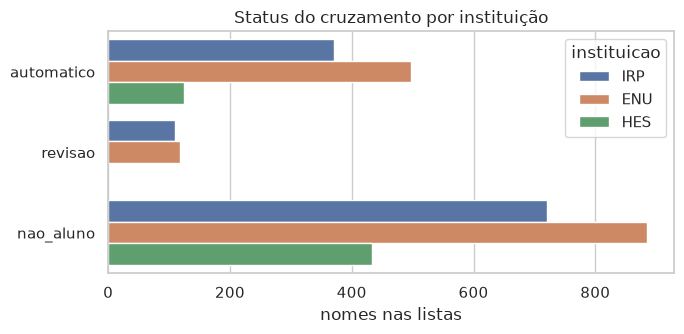

casos
status     motivo                                 
automatico CPF confere e nome parecido         125
           nome praticamente igual             868
nao_aluno  CPF de aluno, mas nome diferente      4
           nenhum aluno com esse CPF           429
           sem nome parecido                  1605
revisao    mais de um aluno com esse nome       13
           nome parecido, mas não igual        214

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ordem = ["automatico", "revisao", "nao_aluno"]
sns.countplot(data=resultado, y="status", order=ordem, hue="instituicao", ax=ax)
ax.set(xlabel="nomes nas listas", ylabel="", title="Status do cruzamento por instituição")
plt.tight_layout()
plt.show()

resultado.groupby(["status", "motivo"]).size().to_frame("casos")

A maior parte dos nomes publicados não é de aluno do cursinho, o que é esperado: o cursinho é um
entre muitos. O que interessa é a qualidade dos casamentos automáticos e o tamanho da fila de revisão.

## 3. O cruzamento acerta?

In [4]:
metricas = avaliar(resultado, gabarito)
pd.Series(metricas).round(3)

automaticos    993.000
acertos        937.000
precisao         0.944
recall           0.891
em_revisao     227.000
perdidos        35.000
dtype: float64

- **Precisão** = dos casamentos automáticos, quantos ligaram o nome ao aluno certo.
- **Recall** = das aprovações de alunos (um aluno aprovado em 3 lugares conta 3 vezes), quantas o
  automático encontrou sozinho.
- **Em revisão** = casos que uma pessoa precisa conferir. Eles não entram na apuração até alguém decidir.
- **Perdidos** = aprovações de alunos que ficaram como "não aluno". Esses são os piores erros, porque
  ninguém volta a olhar para eles.

### De onde vêm os erros do automático?

In [5]:
com_gabarito = resultado.merge(gabarito.rename(columns={"id_aluno": "id_certo"}),
                               on=["instituicao", "inscricao"])
errados = com_gabarito[(com_gabarito["status"] == "automatico")
                       & (com_gabarito["id_aluno"].fillna(-1) != com_gabarito["id_certo"].fillna(-1))]
print(f"{len(errados)} casamentos automáticos errados")
print("Eram de pessoas que não são alunas:", errados["id_certo"].isna().sum())
errados["instituicao"].value_counts()

56 casamentos automáticos errados
Eram de pessoas que não são alunas: 54


instituicao
IRP    28
ENU    28
Name: count, dtype: int64

Quase todos os erros são **homônimos de fora**: um candidato que não é aluno, mas tem exatamente o
mesmo nome de um aluno. Pelo nome não há como distinguir os dois. Por isso não há erros no HES:
ali o CPF parcial desempata. **A lição prática é que o nome sozinho não prova identidade.** Quando a
lista publica CPF, inscrição no CRM ou data de nascimento, vale usar.

## 4. Onde colocar os limiares?

O cruzamento tem dois limiares de similaridade (0 a 100):

- acima do **automático**, aceita sem revisar;
- entre o **de revisão** e o automático, manda para uma pessoa;
- abaixo do de revisão, descarta.

Para escolher, refiz o cruzamento com vários valores e comparei com o gabarito.

Um cuidado: escolher o limiar e medir o resultado com o mesmo gabarito deixa os números um pouco
otimistas, porque o limiar foi ajustado para esses dados. O ideal seria escolher numa lista e medir
em outra.

In [6]:
from apuracao_aprovados.extrair import extrair_todas
from apuracao_aprovados.normalizar import normalizar_especialidade

aprovados = extrair_todas(RAIZ / "data" / "raw")
aprovados["especialidade"] = aprovados["especialidade"].map(normalizar_especialidade)

testes = []
for limiar_auto in [85, 88, 90, 92, 95, 98, 100]:
    m = avaliar(cruzar(aprovados, alunos, limiar_auto=limiar_auto, limiar_revisao=80), gabarito)
    testes.append({"limiar_auto": limiar_auto, **m})
por_auto = pd.DataFrame(testes)
por_auto[["limiar_auto", "precisao", "recall", "em_revisao"]].round(3)

,limiar_auto,precisao,recall,em_revisao
0,85,0.830,0.874,516
1,88,0.907,0.905,573
2,90,0.931,0.904,602
3,92,0.941,0.902,614
4,95,0.944,0.892,629
5,98,0.949,0.858,671
6,100,0.949,0.829,704


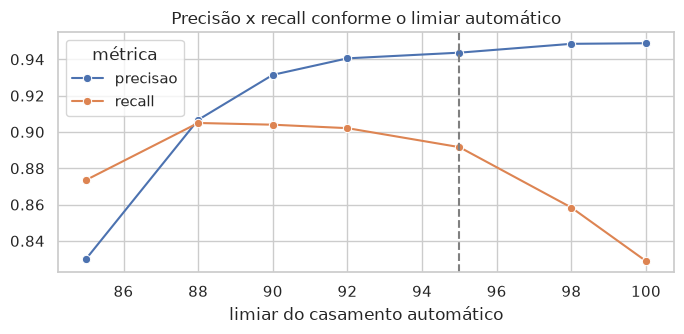

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
grafico = por_auto.melt(id_vars="limiar_auto", value_vars=["precisao", "recall"],
                        var_name="métrica", value_name="valor")
sns.lineplot(data=grafico, x="limiar_auto", y="valor", hue="métrica", marker="o", ax=ax)
ax.axvline(95, color="gray", linestyle="--")
ax.set(xlabel="limiar do casamento automático", ylabel="",
       title="Precisão x recall conforme o limiar automático")
plt.tight_layout()
plt.savefig(IMG / "limiar_automatico.png", dpi=120)
plt.show()

Baixar o limiar automático aumenta um pouco o recall, mas a precisão cai rápido: em 85, cerca de 1
em cada 6 casamentos automáticos estaria errado. A partir de 90 a precisão estabiliza, e em 100 o
recall cai porque qualquer erro de digitação manda o aluno para a revisão. Entre 92 e 95 a precisão
quase não muda; **escolhi 95** por um critério de negócio: numa apuração de aprovados, divulgar um
aluno errado é pior do que conferir alguns casos a mais.

In [8]:
testes = []
for limiar_revisao in [75, 80, 85, 88, 90]:
    m = avaliar(cruzar(aprovados, alunos, limiar_auto=95, limiar_revisao=limiar_revisao), gabarito)
    testes.append({"limiar_revisao": limiar_revisao, **m})
por_revisao = pd.DataFrame(testes)
por_revisao[["limiar_revisao", "em_revisao", "perdidos"]]

,limiar_revisao,em_revisao,perdidos
0,75,1201,2
1,80,629,8
2,85,227,35
3,88,100,62
4,90,47,90


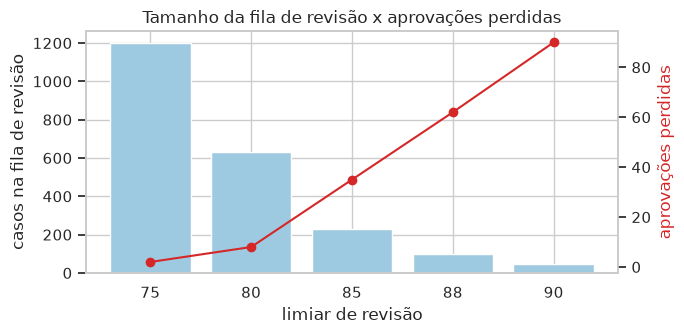

In [9]:
fig, ax1 = plt.subplots(figsize=(7, 3.5))
ax1.bar(por_revisao["limiar_revisao"].astype(str), por_revisao["em_revisao"], color="#9ecae1")
ax1.set(xlabel="limiar de revisão", ylabel="casos na fila de revisão")
ax2 = ax1.twinx()
ax2.plot(por_revisao["limiar_revisao"].astype(str), por_revisao["perdidos"], color="#d62728", marker="o")
ax2.set_ylabel("aprovações perdidas", color="#d62728")
ax2.grid(False)
ax1.set_title("Tamanho da fila de revisão x aprovações perdidas")
plt.tight_layout()
plt.savefig(IMG / "limiar_revisao.png", dpi=120)
plt.show()

Aqui a troca é entre trabalho manual e aprovações perdidas. Com 80, a fila tem centenas de casos e a
grande maioria é de não alunos com nome parecido. Com 85, a fila cai para cerca de um terço e se
perdem só algumas dezenas de aprovações a mais. **Escolhi 85.** Num período de pico de apuração, uma
fila menor é o que permite entregar no prazo. O custo é aceito conscientemente e fica registrado.

## 5. Resultado da apuração (SQL)

In [10]:
consultas = ler_consultas()
list(consultas)

['Resumo: quantos alunos passaram e quantas aprovações eles somam',
 'Participação do cursinho em cada lista',
 'Aprovações de alunos por especialidade',
 'Taxa de aprovação por turma (aluno aprovado em pelo menos uma instituição)',
 'Alunos aprovados em mais de uma instituição',
 'Melhor classificação de cada aluno (função de janela) e quem ficou entre os 3 primeiros',
 'Fila de revisão manual: o que falta conferir e por quê']

In [11]:
for titulo in list(consultas)[:2]:
    print("##", titulo)
    display(consultar(BANCO, consultas[titulo]))

## Resumo: quantos alunos passaram e quantas aprovações eles somam


,alunos_aprovados,aprovacoes
0,830,993


## Participação do cursinho em cada lista


,instituicao,aprovados_na_lista,alunos_do_cursinho,pct_da_lista,pendentes_de_revisao
0,ENU,1500,497,33.1,118
1,IRP,1200,371,30.9,109
2,HES,558,125,22.4,0


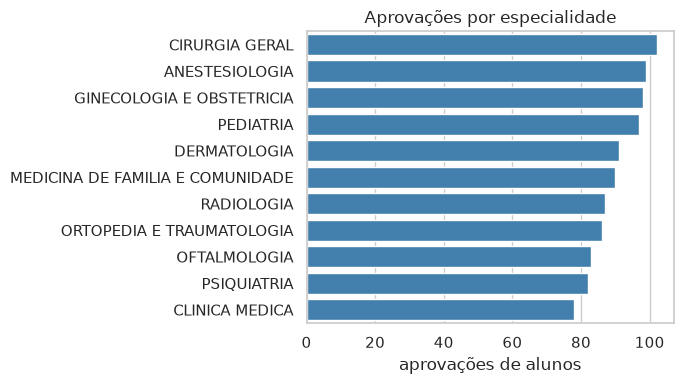

In [12]:
por_especialidade = consultar(BANCO, consultas["Aprovações de alunos por especialidade"])
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=por_especialidade, y="especialidade", x="aprovacoes", color="#3182bd", ax=ax)
ax.set(xlabel="aprovações de alunos", ylabel="", title="Aprovações por especialidade")
plt.tight_layout()
plt.savefig(IMG / "por_especialidade.png", dpi=120)
plt.show()

In [13]:
for titulo in list(consultas)[3:]:
    print("##", titulo)
    display(consultar(BANCO, consultas[titulo]).head(10))

## Taxa de aprovação por turma (aluno aprovado em pelo menos uma instituição)


,turma,alunos,aprovados,taxa_aprovacao
0,Extensivo 2026,496,218,44.0
1,Extensivo 2025,531,225,42.4
2,R+ Clínica 2026,504,207,41.1
3,Intensivo 2026,469,180,38.4


## Alunos aprovados em mais de uma instituição


,nome,turma,instituicoes,onde
0,Carolina Aparecida Andrade de Gomes de Cardoso,Extensivo 2025,3,"IRP,ENU,HES"
1,Isabela Eduarda Santana Brandao Andrade,R+ Clínica 2026,3,"IRP,ENU,HES"
2,Marcelo Cavalcanti,Extensivo 2026,3,"IRP,ENU,HES"
3,Matheus Henrique Carvalho Dias Marques,Intensivo 2026,3,"IRP,ENU,HES"
4,Rafaela Eduarda Lima,Extensivo 2026,3,"IRP,ENU,HES"
5,camila helena nascimento de freitas,Extensivo 2025,3,"IRP,ENU,HES"
6,feranda marques dias,Intensivo 2026,3,"IRP,ENU,HES"
7,Amanda Fernanda Ramos da Rocha,Extensivo 2025,2,"IRP,HES"
8,Amanda Carolina Lima,R+ Clínica 2026,2,"IRP,ENU"
9,Amanda Carolina Moreira,Extensivo 2025,2,"IRP,ENU"


## Melhor classificação de cada aluno (função de janela) e quem ficou entre os 3 primeiros


,nome,instituicao,especialidade,classificacao
0,Camila Brandao Nunes,IRP,OFTALMOLOGIA,1
1,Juliana Luísa Carvalho Moura,ENU,PEDIATRIA,1
2,Leonardo Machado de Alves,IRP,CLINICA MEDICA,1
3,Mariana Eduarda Monteiro Ramos,ENU,ORTOPEDIA E TRAUMATOLOGIA,1
4,Patrícia Magalhães Teixeira,ENU,OFTALMOLOGIA,1
5,Rafael Almeida Carvalho,ENU,MEDICINA DE FAMILIA E COMUNIDADE,1
6,gustavo batista lopes,ENU,GINECOLOGIA E OBSTETRICIA,1
7,Carolina Luísa Santos de Moura,IRP,PSIQUIATRIA,2
8,Isabela Batista,ENU,MEDICINA DE FAMILIA E COMUNIDADE,2
9,Isabela Lima de Cavalcanti Conceição,IRP,OFTALMOLOGIA,2


## Fila de revisão manual: o que falta conferir e por quê


,instituicao,motivo,casos
0,ENU,"nome parecido, mas não igual",113
1,IRP,"nome parecido, mas não igual",101
2,IRP,mais de um aluno com esse nome,8
3,ENU,mais de um aluno com esse nome,5


## Conclusões

- A extração recuperou **todos** os aprovados dos três PDFs, mesmo com layouts diferentes, nomes
  quebrados em duas linhas e lista de espera misturada.
- Com os limiares escolhidos (95 e 85), o casamento automático acerta cerca de **94%** das vezes e
  encontra perto de **90%** das aprovações de alunos sem ajuda. Uma fila de pouco mais de 200 casos
  fica para revisão manual.
- Quase todo erro do automático é um **homônimo** que não é aluno. Onde há CPF parcial (HES), esse
  erro some. Pedir aos alunos que confirmem a aprovação, ou usar um identificador quando a lista
  publica um, resolveria o resto.
- As diferenças de taxa de aprovação entre turmas e especialidades **não devem ser interpretadas**:
  nos dados sintéticos, a aprovação foi sorteada com a mesma chance para todos.

## Limitações

- O total de alunos aprovados (consulta 1) inclui os casamentos automáticos errados, então é uma
  estimativa um pouco para cima.
- Dados sintéticos. Listas reais têm problemas que não simulei, como nomes sociais, nomes trocados
  após casamento, PDFs digitalizados (imagem, que exigiria OCR) e mudanças de layout de um ano para outro.
- O gabarito só existe porque os dados são inventados. Na prática, a qualidade seria medida
  conferindo uma amostra à mão.
- `token_sort_ratio` é uma escolha simples. Uma melhoria seria combinar mais de uma medida de
  similaridade ou dar peso diferente ao primeiro e ao último nome.